# 04b — Train và đánh giá IDS cửa sổ lai theo gói (N gói hoặc T giây)

Dữ liệu từ `03b` (`windows_pkt/`). **v3: một model 4 lớp** `benign` / `recon` / `bruteforce` / `dos` (DoS từ TII-SSRC-23 qua `01c`), cùng cửa sổ và 97 đặc trưng như trước. Báo cáo thêm báo động trên nền khó: `benign_tii`, và từ v5 `benign_qos` (app tiêu dùng, theo nhóm app) và `benign_zt` (ZeroTier) từ `01d`, theo nguồn, loại traffic và từng file. Giống 04 về ngưỡng và cách đánh giá; thêm phần **giảm overfit**:

- `hgb`: so vài cấu hình từ v2 (cây 31 lá) tới cấu hình ràng buộc mạnh hơn — ít lá hơn / nông hơn, `min_samples_leaf` lớn,
  L2 mạnh, mỗi lần tách chỉ xét một phần đặc trưng (`max_features`), learning rate nhỏ.
  Mỗi cấu hình train 500 vòng, lấy vòng có **val loss có trọng số** nhỏ nhất; chọn cấu hình có val loss nhỏ nhất,
  báo kèm chênh lệch val − train loss tại vòng đó.
- Ngưỡng trên val (từ v5b): **số đợt** báo động sai ≤ `TARGET_FP_EPISODES_PER_HOUR` trên ngày nền val (đợt: cùng host,
  các cửa sổ báo động cách nhau ≤ 60 s). Trước v5b tính theo **cửa sổ** (0,2 cửa sổ/giờ): một máy UNSW upload dài
  (`.237`, ngày 16-10-07) sinh hàng chục cửa sổ giống DoS, chiếm hết 19 cửa sổ cho phép và đẩy ngưỡng lên 0,993
  → trên router quét thật chỉ được 0,75–0,97 điểm mà không báo. Tính theo đợt thì một sự kiện kéo dài chỉ tính một lần.
  Lịch sử: mục tiêu 0,2/giờ (không phải 1/giờ): val chỉ ~96 giờ / 4 ngày nên ước lượng FP rất nhiễu — ở pkt v1 ngưỡng chọn cho
  1/giờ trên val cho 13/giờ trên test (máy tính bảng, laptop, điện thoại có đợt kết nối dồn dập giống quét).
  Cửa sổ tấn công hầu hết có điểm ≈ 1 nên nâng ngưỡng gần như không mất phát hiện.
  Báo cáo thêm số **đợt báo động** (cùng host, các cửa sổ báo động cách nhau ≤ 60 s gộp một).
  Báo cáo thêm số khối 10 s có báo động (host × 10 s) để so với run cửa sổ 10 s (`Model/hgb`).
- Chạy nhanh: chỉ train cấu hình trong `RUN_CONFIGS` (mặc định `D_nong`, tốt nhất khi so cả lưới ở pkt v1);
  lịch sử train tính mỗi `HIST_EVERY` vòng trên mẫu `HIST_SAMPLE` cửa sổ train; CSV được cache sang `.parquet`.
- Lưu: `Model/hgb_pkt/<YYYYMMDD_HHMM>/` + `runs.csv`. Đã bỏ `dtree` (pkt v1: ngưỡng 0,9995, phát hiện 2,4% task).

In [1]:
import itertools, json, time
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, log_loss
from threadpoolctl import threadpool_limits

N_THREADS = 44  # máy dùng chung (88 lõi): HGB mặc định dùng OpenMP trên mọi lõi -> giới hạn cho cả notebook
threadpool_limits(limits=N_THREADS)

ROOT = Path('/home/ubuntu/sepcung/03.Brute_Force_vs_Recon')
WIN_DIR = ROOT / 'Data_after_processing' / 'windows_pkt'
MODEL_ROOT = ROOT / 'Model'
MODEL_DIR = {'hgb': 'hgb_pkt'}
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M')
RUN_NOTE = ('pkt v5b: nền khó QoS (tách gói gộp, gỡ NAT) + ZeroTier mô phỏng (01d), tăng cường DoS thêm mảnh IP '
            'cho ICMP/UDP, ngưỡng theo đợt báo nhầm (0,15 đợt/giờ val); còn lại như v4')
WINDOW = {'n_pkt': 50, 't_max': 10, 'ctx': [60, 300], 'new_gap': 300}  # khớp 03b

TARGET_FP_EPISODES_PER_HOUR = 0.15  # đợt báo động sai/giờ trên val; chặt hơn mục tiêu thật (1/giờ) để bù sai lệch val → test
EPISODE_GAP_S = 60  # gộp cửa sổ báo động cùng host cách nhau ≤ 60 s thành một đợt
CLASSES = ['benign', 'recon', 'bruteforce', 'dos']
CLASS_NAMES = {'benign': 'Benign', 'recon': 'Recon', 'bruteforce': 'Bruteforce', 'dos': 'DoS'}
LABELS = list(range(len(CLASSES)))
ATTACKER_IP, TARGET_IP = '192.168.1.236', '192.168.1.182'
HARD_SOURCES = ['benign_tii', 'benign_qos', 'benign_zt']  # nền khó (03b): TII, QoS (01d), ZeroTier (01d)

HGB_BASE = {'max_iter': 500, 'early_stopping': False, 'random_state': 42}
HGB_GRID = {
    'A_v2': {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
    'B_nho': {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 5.0},
    'C_nho_feat': {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 5.0,
                   'max_features': 0.5},
    'D_nong': {'learning_rate': 0.05, 'max_depth': 4, 'max_leaf_nodes': 15, 'min_samples_leaf': 200,
               'l2_regularization': 10.0, 'max_features': 0.5},
}
RUN_CONFIGS = ['D_nong']  # pkt v1 đã so cả lưới, D_nong có val loss nhỏ nhất; đặt list(HGB_GRID) để so lại
HIST_EVERY, HIST_SAMPLE = 5, 200_000  # lịch sử train: mỗi 5 vòng, trên mẫu 200k cửa sổ train


def make_hgb(cfg, **kw):
    return HistGradientBoostingClassifier(**{**HGB_BASE, **HGB_GRID[cfg], **kw})


def load(s):
    csv, pq = WIN_DIR / f'{s}.csv', WIN_DIR / f'{s}.parquet'  # cache parquet, tạo lại khi CSV mới hơn
    if not pq.exists() or pq.stat().st_mtime < csv.stat().st_mtime:
        pd.read_csv(csv, low_memory=False).to_parquet(pq, index=False)
    df = pd.read_parquet(pq)
    f = [c for c in df if c.startswith('f_')]
    df[f] = df[f].astype(np.float32)  # model chỉ nhận float32: giữ đặc trưng float32 cho nhẹ RAM (máy dùng chung, từng bị OOM)
    return df


data = {s: load(s) for s in ['train', 'val', 'test']}
FEATURES = [c for c in data['train'].columns if c.startswith('f_')]
hours = {s: d.loc[d['source'] == 'benign_day'].groupby('day')['t_end'].agg(lambda t: (t.max() - t.min()) / 3600).sum()
         for s, d in data.items()}
pd.DataFrame({s: {'rows': len(d), 'use_train': int(d['use_train'].sum()), 'benign_hours': round(hours[s], 1)}
              for s, d in data.items()})

,train,val,test
rows,2709640.0,728926.0,748187.0
use_train,2172455.0,561231.0,575804.0
benign_hours,278.5,96.0,95.0


In [2]:
pd.concat({s: d.groupby(['source', 'label']).size() for s, d in data.items()}, axis=1).fillna(0).astype(int)

train     val    test
source     label                              
benign_day benign       787145  255621  271582
benign_qos benign       101666   28294   32343
benign_tii benign        38569    8269    8255
benign_zt  benign        76553   13864      13
mix        benign        26610    5108   10675
           bruteforce   288159  133298  139587
           dos          765840   97245  101742
           post_attack   12267     732    2710
           recon         87913   19532   11607
           victim       524918  166963  169673

## 1. `hgb`: chọn cấu hình chống overfit theo val loss

In [3]:
tr = data['train'][data['train']['use_train'] == 1]
va = data['val'][data['val']['use_train'] == 1]
to_y = lambda df: df['label'].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
X_tr, y_tr, w_tr = tr[FEATURES].to_numpy(np.float32), to_y(tr), tr['sample_weight'].to_numpy()
X_va, y_va, w_va = va[FEATURES].to_numpy(np.float32), to_y(va), va['sample_weight'].to_numpy()
wloss = lambda y, p, w: log_loss(y, p, sample_weight=w, labels=LABELS)

grid_rows, grid_models, grid_curves = [], {}, {}
for cfg in RUN_CONFIGS:
    t0 = time.time()
    m = make_hgb(cfg).fit(X_tr, y_tr, sample_weight=w_tr)
    vl = np.array([wloss(y_va, p, w_va) for p in m.staged_predict_proba(X_va)])
    best = int(vl.argmin()) + 1
    tl = wloss(y_tr, next(itertools.islice(m.staged_predict_proba(X_tr), best - 1, None)), w_tr)
    grid_models[cfg], grid_curves[cfg] = m, vl
    grid_rows.append({'config': cfg, 'best_iter': best, 'train_loss': tl, 'val_loss': vl[best - 1],
                      'gap': vl[best - 1] - tl, 'val_loss_last': vl[-1], 'fit_s': round(time.time() - t0, 1)})
    print(grid_rows[-1])
grid = pd.DataFrame(grid_rows).set_index('config')
CFG = grid['val_loss'].idxmin()
print('cấu hình chọn:', CFG)
grid.round(5)

{'config': 'D_nong', 'best_iter': 419, 'train_loss': 3.7709132258752176e-05, 'val_loss': 0.0037782393636933338, 'gap': 0.0037405302314345817, 'val_loss_last': 0.003888515794631214, 'fit_s': 328.1}
cấu hình chọn: D_nong


,best_iter,train_loss,val_loss,gap,val_loss_last,fit_s
config,,,,,,
D_nong,419,0.00004,0.00378,0.00374,0.00389,328.1


In [4]:
# Lịch sử theo vòng của cấu hình được chọn (có và không trọng số), rồi train lại đúng BEST_ITER vòng
m_full = grid_models[CFG]
BEST_ITER = int(grid.loc[CFG, 'best_iter'])
iters = np.array([i for i in range(1, m_full.n_iter_ + 1) if i % HIST_EVERY == 0 or i in (1, BEST_ITER, m_full.n_iter_)])
i_hist = np.random.default_rng(42).choice(len(X_tr), min(HIST_SAMPLE, len(X_tr)), replace=False)
hist = {'iteration': iters}
for split_name, (X, y, w) in {'train': (X_tr[i_hist], y_tr[i_hist], w_tr[i_hist]), 'validation': (X_va, y_va, w_va)}.items():
    cols = {k: [] for k in ['accuracy', 'loss', 'accuracy_unweighted', 'loss_unweighted']}
    for it, p in enumerate(m_full.staged_predict_proba(X), 1):
        if it not in iters:
            continue
        pred = p.argmax(axis=1)
        cols['accuracy'].append(accuracy_score(y, pred, sample_weight=w))
        cols['loss'].append(wloss(y, p, w))
        cols['accuracy_unweighted'].append(accuracy_score(y, pred))
        cols['loss_unweighted'].append(log_loss(y, p, labels=LABELS))
    for k, v in cols.items():
        hist[f'{split_name}_{k}'] = v
hist = pd.DataFrame(hist)
fitted = {'hgb': make_hgb(CFG, max_iter=BEST_ITER).fit(X_tr, y_tr, sample_weight=w_tr)}
p_staged = next(itertools.islice(m_full.staged_predict_proba(X_va), BEST_ITER - 1, None))
print('BEST_ITER', BEST_ITER, '| model train lại khớp vòng đã chọn:',
      np.allclose(fitted['hgb'].predict_proba(X_va), p_staged, atol=1e-6))

BEST_ITER 419 | model train lại khớp vòng đã chọn: True


## 2. Ngưỡng trên val theo báo động sai/giờ

In [5]:
def score(m, df):
    p = m.predict_proba(df[FEATURES].to_numpy(np.float32))
    return 1 - p[:, 0], np.array(CLASSES[1:])[p[:, 1:].argmax(axis=1)]


def pick_threshold(bdf, scores, hrs, target):
    """Ngưỡng thấp nhất (≥ 0,05) sao cho số đợt báo động sai trên nền val ≤ target × giờ; đợt = cùng (ngày, host),
    các cửa sổ báo động cách nhau ≤ EPISODE_GAP_S. Ngưỡng đặt cách điểm cửa sổ đầu tiên bị loại ≤ 1e-4 (không quá nửa
    khoảng tới điểm kế trên) để ONNX/router tính float32 không lật quyết định."""
    k = int(np.floor(target * hrs))
    d = bdf[['day', 'host', 't_end']].assign(s=scores)
    d = d[d['s'] >= 0.05].sort_values(['day', 'host', 't_end'])

    def n_ep(t):
        x = d[d['s'] >= t]
        return int((x.groupby(['day', 'host'])['t_end'].diff().fillna(np.inf) > EPISODE_GAP_S).sum())

    prev = 1.0
    for c in np.sort(d['s'].unique())[::-1]:
        if n_ep(c) > k:
            return float(c + min(1e-4, (prev - c) / 2))
        prev = c
    return 0.05


thr = {}
for name, m in fitted.items():
    v = data['val']
    vb = v[v['source'] == 'benign_day']
    sc, _ = score(m, vb)
    thr[name] = pick_threshold(vb, sc, hours['val'], TARGET_FP_EPISODES_PER_HOUR)
thr

{'hgb': 0.9928104801023478}

## 3. Đánh giá trên test

In [6]:
def evaluate(name, m, df, hrs):
    sc, cls = score(m, df)
    d = df[['source', 'day', 'sample_id', 'scenario', 'incomplete_capture', 'host', 't_start', 't_end', 'b10',
            'label', 'use_train']].copy()
    d['score'], d['alarm'] = sc, sc >= thr[name]
    d['pred'] = np.where(d['alarm'], cls, 'benign')
    res = {}
    bd = d[d['source'] == 'benign_day']
    res['fp_per_hour'] = bd['alarm'].sum() / hrs
    res['fp_alarm_10s_per_hour'] = len(bd.loc[bd['alarm'], ['day', 'host', 'b10']].drop_duplicates()) / hrs
    ba = bd[bd['alarm']].sort_values(['day', 'host', 't_end'])
    res['fp_episode_per_hour'] = (ba.groupby(['day', 'host'])['t_end'].diff().fillna(np.inf) > EPISODE_GAP_S).sum() / hrs
    res['fp_hosts'] = bd[bd['alarm']].groupby('host').size().sort_values(ascending=False).head(10).to_dict()
    mixb = d[(d['source'] == 'mix') & (d['label'] == 'benign')]
    res['persona_benign_alarm_rate'] = mixb.loc[mixb['host'] == ATTACKER_IP, 'alarm'].mean()
    res['target_benign_alarm_rate'] = mixb.loc[mixb['host'] == TARGET_IP, 'alarm'].mean()
    res['victim_alarm_rate'] = d.loc[d['label'] == 'victim', 'alarm'].mean()
    vic = d[d['label'] == 'victim']
    res['victim_alarm_rate_dos'] = vic.loc[vic['scenario'].fillna('').str.startswith('dos_'), 'alarm'].mean()
    tb = d[d['source'] == 'benign_tii']  # nền khó: video/audio/text TII, cùng cặp máy với DoS
    res['tii_benign_alarm_rate'] = tb['alarm'].mean()
    res['tii_benign_alarm_by_part'] = tb.groupby('day')['alarm'].agg(['size', 'sum']).to_dict('index')
    # mọi nguồn nền khó: tỉ lệ cửa sổ báo động theo nguồn, loại traffic (scenario: qos_<nhóm>, zerotier) và file (day)
    hb = d[d['source'].isin(HARD_SOURCES)].assign(scenario=lambda x: x['scenario'].fillna(''))
    res['hard_alarm_rate'] = {s: hb.loc[hb['source'] == s, 'alarm'].mean() for s in HARD_SOURCES}
    agg = dict(windows=('alarm', 'size'), alarms=('alarm', 'sum'), alarm_rate=('alarm', 'mean'),
               top_pred=('pred', lambda p: p[p != 'benign'].mode().iat[0] if (p != 'benign').any() else ''))
    res['hard_by_scenario'] = hb.groupby(['source', 'scenario']).agg(**agg).reset_index()
    res['hard_by_part'] = (hb.groupby(['source', 'day']).agg(**agg).reset_index()
                           .sort_values(['alarms', 'alarm_rate'], ascending=False, ignore_index=True))

    att = d[d['label'].isin(CLASSES[1:])]
    per_task = att.groupby('sample_id').apply(lambda g: pd.Series({
        'scenario': g['scenario'].iat[0], 'class': g['label'].iat[0], 'incomplete_capture': g['incomplete_capture'].iat[0],
        'attack_windows': len(g), 'alarm_windows': int(g['alarm'].sum()),
        'detected': bool(g['alarm'].any()),
        'delay_s': (g.loc[g['alarm'], 't_end'].min() - g['t_start'].min()) if g['alarm'].any() else np.nan,
        'class_correct': (g.loc[g['alarm'], 'pred'].mode().iat[0] == g['label'].iat[0]) if g['alarm'].any() else False,
    }), include_groups=False).reset_index()
    per_scen = per_task.groupby(['incomplete_capture', 'scenario']).agg(
        tasks=('sample_id', 'size'), detect_rate=('detected', 'mean'), class_acc=('class_correct', 'mean'),
        window_recall=('alarm_windows', lambda s: s.sum() / per_task.loc[s.index, 'attack_windows'].sum()),
        median_delay_s=('delay_s', 'median')).reset_index()
    u = d[d['use_train'] == 1]
    res['report'] = classification_report(u['label'], u['pred'], labels=CLASSES, output_dict=True, zero_division=0)
    res['cm'] = pd.DataFrame(confusion_matrix(u['label'], u['pred'], labels=CLASSES),
                             index=[f'true_{c}' for c in CLASSES], columns=[f'pred_{c}' for c in CLASSES])
    comp = per_scen[per_scen['incomplete_capture'] == 0]
    res['task_detect_rate'] = float((comp['detect_rate'] * comp['tasks']).sum() / comp['tasks'].sum())
    res['median_delay_s'] = float(per_task.loc[per_task['incomplete_capture'] == 0, 'delay_s'].median())
    return res, per_task, per_scen


results = {}
for name, m in fitted.items():
    results[name] = evaluate(name, m, data['test'], hours['test'])
    r = results[name][0]
    print(f"== {name}: thr={thr[name]:.4f}  FP cửa sổ/giờ={r['fp_per_hour']:.2f}  FP khối 10s/giờ={r['fp_alarm_10s_per_hour']:.2f}  "
          f"FP đợt/giờ={r['fp_episode_per_hour']:.2f}  "
          f"phát hiện task={r['task_detect_rate']:.3f}  trễ trung vị={r['median_delay_s']:.2f}s")
    print(f"   persona benign alarm={r['persona_benign_alarm_rate']:.3f}  camera benign alarm={r['target_benign_alarm_rate']:.3f}  "
          f"victim alarm={r['victim_alarm_rate']:.3f} (DoS: {r['victim_alarm_rate_dos']:.3f})")
    print(f"   benign TII: tỉ lệ cửa sổ báo động={r['tii_benign_alarm_rate']:.4f}", r['tii_benign_alarm_by_part'])
    print('   nền khó, tỉ lệ cửa sổ báo động:', {s: round(v, 4) for s, v in r['hard_alarm_rate'].items()})
    display(r['hard_by_scenario'].round(4))
    display(r['hard_by_part'].head(15).round(4))
    print('   host báo sai nhiều nhất:', r['fp_hosts'])
    display(r['cm'])
    display(results[name][2].round(3))

== hgb: thr=0.9928  FP cửa sổ/giờ=0.00  FP khối 10s/giờ=0.00  FP đợt/giờ=0.00  phát hiện task=0.962  trễ trung vị=5.64s
   persona benign alarm=0.000  camera benign alarm=0.000  victim alarm=0.004 (DoS: 0.060)
   benign TII: tỉ lệ cửa sổ báo động=0.0000 {'audio': {'size': 2250, 'sum': 0}, 'text': {'size': 152, 'sum': 0}, 'video_http': {'size': 2424, 'sum': 0}, 'video_rtp': {'size': 1762, 'sum': 0}, 'video_udp': {'size': 1667, 'sum': 0}}
   nền khó, tỉ lệ cửa sổ báo động: {'benign_tii': 0.0, 'benign_qos': 0.0, 'benign_zt': 0.0}


,source,scenario,windows,alarms,alarm_rate,top_pred
0,benign_qos,qos_background,243,0,0.0,
1,benign_qos,qos_download,5277,0,0.0,
2,benign_qos,qos_game,4991,0,0.0,
3,benign_qos,qos_longvideo,7149,0,0.0,
4,benign_qos,qos_shortvideo,7204,0,0.0,
5,benign_qos,qos_videocall,5314,0,0.0,
6,benign_qos,qos_voicecall,2165,0,0.0,
7,benign_tii,,8255,0,0.0,
8,benign_zt,zerotier,13,0,0.0,


,source,day,windows,alarms,alarm_rate,top_pred
0,benign_qos,Videocall_MSTeam_5_pc,338,0,0.0,
1,benign_qos,Videocall_Meet_5_pc,859,0,0.0,
2,benign_qos,Videocall_Mess_5_pc,317,0,0.0,
3,benign_qos,Videocall_Zalo_5_pc,232,0,0.0,
4,benign_qos,Videocall_Zoom_5_pc,260,0,0.0,
5,benign_qos,Videocall_meet_5_ios,473,0,0.0,
6,benign_qos,Videocall_mess_5_ios,218,0,0.0,
7,benign_qos,Videocall_msteam_5_ios,405,0,0.0,
8,benign_qos,Videocall_zalo_5_ios,323,0,0.0,
9,benign_qos,Videocall_zoom_5_ios,469,0,0.0,


   host báo sai nhiều nhất: {}


,pred_benign,pred_recon,pred_bruteforce,pred_dos
true_benign,322868,0,0,0
true_recon,328,11279,0,0
true_bruteforce,41,0,139546,0
true_dos,8887,2,0,92853


,incomplete_capture,scenario,tasks,detect_rate,class_acc,window_recall,median_delay_s
0,0.0,dos_ack,8,1.000,1.000,1.000,0.104
1,0.0,dos_fin,8,1.000,1.000,1.000,0.123
2,0.0,dos_icmp,4,0.500,0.500,0.455,0.160
3,0.0,dos_rst,8,1.000,1.000,1.000,0.062
4,0.0,dos_syn,8,1.000,1.000,0.985,0.115
5,0.0,dos_udp,8,0.875,0.875,0.810,0.039
6,0.0,firewall_ack_mapping,38,0.947,0.947,0.867,10.000
7,0.0,ssh,44,1.000,1.000,1.000,8.058
8,0.0,stealth_fin_scan,2,1.000,1.000,1.000,7.549
9,0.0,stealth_null_scan,2,1.000,1.000,1.000,6.212


## 4. `arp_discovery`: leave-one-task-out (model `hgb`)

In [7]:
loto = []
arp_ids = data['train'].loc[data['train']['scenario'] == 'arp_discovery', 'sample_id'].unique()
for sid in arp_ids:
    keep = (tr['sample_id'] != sid).to_numpy()
    m = make_hgb(CFG, max_iter=BEST_ITER).fit(X_tr[keep], y_tr[keep], sample_weight=w_tr[keep])
    held = data['train'][(data['train']['sample_id'] == sid) & (data['train']['label'] == 'recon')]
    sc, cls = score(m, held)
    loto.append({'sample_id': sid, 'attack_windows': len(held), 'alarm_windows': int((sc >= thr['hgb']).sum()),
                 'max_score': float(sc.max()), 'pred_class': pd.Series(cls[sc >= thr['hgb']]).mode().tolist()})
loto = pd.DataFrame(loto)
loto

,sample_id,attack_windows,alarm_windows,max_score,pred_class
0,arp_discovery_0001,10,0,0.991900,[]
1,arp_discovery_0002,10,7,0.998757,[recon]


## 5. Lưu model và báo cáo theo thời gian

In [8]:
inputs = {s: {'path': str(WIN_DIR / f'{s}.csv'),
              'mtime': datetime.fromtimestamp((WIN_DIR / f'{s}.csv').stat().st_mtime).isoformat()}
          for s in ['train', 'val', 'test']}
for name, m in fitted.items():
    run_dir = MODEL_ROOT / MODEL_DIR[name] / RUN_ID
    run_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump({'model': m, 'features': FEATURES, 'classes': CLASSES, 'threshold': thr[name], 'window': WINDOW},
                run_dir / 'model.joblib')
    r, per_task, per_scen = results[name]
    per_task.to_csv(run_dir / 'test_per_task.csv', index=False)
    per_scen.to_csv(run_dir / 'test_per_scenario.csv', index=False)
    r['cm'].to_csv(run_dir / 'test_confusion_matrix.csv')
    r['hard_by_scenario'].to_csv(run_dir / 'test_hard_benign_by_scenario.csv', index=False)
    r['hard_by_part'].to_csv(run_dir / 'test_hard_benign_by_part.csv', index=False)
    pd.DataFrame(r['report']).T.to_csv(run_dir / 'test_classification_report.csv')
    loto.to_csv(run_dir / 'arp_discovery_loto.csv', index=False)
    grid.to_csv(run_dir / 'config_grid.csv')
    sel = grid.loc[CFG]
    extra = {'config': CFG, 'best_iter': BEST_ITER}
    cfg = {'run_id': RUN_ID, 'note': RUN_NOTE, 'model': name, 'params': m.get_params(), **extra, 'window': WINDOW,
           'threshold': thr[name], 'target_fp_episodes_per_hour': TARGET_FP_EPISODES_PER_HOUR, 'n_features': len(FEATURES), 'inputs': inputs}
    (run_dir / 'run_config.json').write_text(json.dumps(cfg, ensure_ascii=False, indent=2, default=str))
    row = {'run_id': RUN_ID, 'note': RUN_NOTE, **extra, 'train_loss': sel['train_loss'], 'val_loss': sel['val_loss'],
           'threshold': thr[name], 'fp_per_hour_test': r['fp_per_hour'], 'fp_alarm_10s_per_hour_test': r['fp_alarm_10s_per_hour'],
           'fp_episode_per_hour_test': r['fp_episode_per_hour'],
           'task_detect_rate_test': r['task_detect_rate'], 'median_delay_s_test': r['median_delay_s'],
           'macro_f1_test': r['report']['macro avg']['f1-score'], 'persona_benign_alarm_rate': r['persona_benign_alarm_rate'],
           'tii_benign_alarm_rate_test': r['tii_benign_alarm_rate'],
           'qos_benign_alarm_rate_test': r['hard_alarm_rate']['benign_qos'],
           'zt_benign_alarm_rate_test': r['hard_alarm_rate']['benign_zt'], 'victim_alarm_rate_test': r['victim_alarm_rate'],
           'classes': '/'.join(CLASSES)}
    runs = MODEL_ROOT / MODEL_DIR[name] / 'runs.csv'
    pd.concat([pd.read_csv(runs) if runs.exists() else None, pd.DataFrame([row])]).to_csv(runs, index=False)
    print(name, '->', run_dir)

hgb -> /home/ubuntu/sepcung/03.Brute_Force_vs_Recon/Model/hgb_pkt/20261111_1058


## 6. So với run cửa sổ 10 s gần nhất (`Model/hgb`)

FP của run cửa sổ 10 s là số cửa sổ (host × 10 s) báo động → so với cột "khối 10 s" của run này.

In [9]:
old_runs = MODEL_ROOT / 'hgb' / 'runs.csv'
if not old_runs.exists():
    print(f'Bỏ qua so sánh: không có {old_runs} (run cửa sổ 10 s)')
else:
    old = pd.read_csv(old_runs).iloc[-1]
    old_hist = pd.read_csv(MODEL_ROOT / 'hgb' / old['run_id'] / 'train_history.csv')
    ob = old_hist.loc[old_hist['validation_loss'].idxmin()]
    r = results['hgb'][0]
    display(pd.DataFrame({
        f"cửa sổ 10 s ({old['run_id']})": {
            'train loss @ vòng chọn': ob['train_loss'], 'val loss @ vòng chọn': ob['validation_loss'],
            'chênh val − train': ob['validation_loss'] - ob['train_loss'],
            'FP/giờ (khối 10 s)': old['fp_per_hour_test'], 'phát hiện task (capture đủ)': old['task_detect_rate_test'],
            'macro F1 (cửa sổ)': old['macro_f1_test'], 'persona benign alarm': old['persona_benign_alarm_rate']},
        f'cửa sổ lai ({RUN_ID}, {CFG})': {
            'train loss @ vòng chọn': grid.loc[CFG, 'train_loss'], 'val loss @ vòng chọn': grid.loc[CFG, 'val_loss'],
            'chênh val − train': grid.loc[CFG, 'gap'],
            'FP/giờ (khối 10 s)': r['fp_alarm_10s_per_hour'], 'phát hiện task (capture đủ)': r['task_detect_rate'],
            'macro F1 (cửa sổ)': r['report']['macro avg']['f1-score'], 'persona benign alarm': r['persona_benign_alarm_rate']},
    }).round(4))


Bỏ qua so sánh: không có /home/ubuntu/sepcung/03.Brute_Force_vs_Recon/Model/hgb/runs.csv (run cửa sổ 10 s)


## 7. Hình: confusion matrix, train history, so sánh cấu hình

- **Confusion matrix** trên test (bỏ 3 kịch bản host discovery thiếu ARP), ô ghi tỷ lệ theo hàng và (số cửa sổ); bản 2 lớp và đủ lớp.
- **Train history** của `hgb` cấu hình được chọn trên đủ 500 vòng; đường đứt là vòng chọn theo val loss.
- **Val loss theo vòng** của các cấu hình trong lưới.

== hgb (ngưỡng 0.9928, 570,932 cửa sổ test)


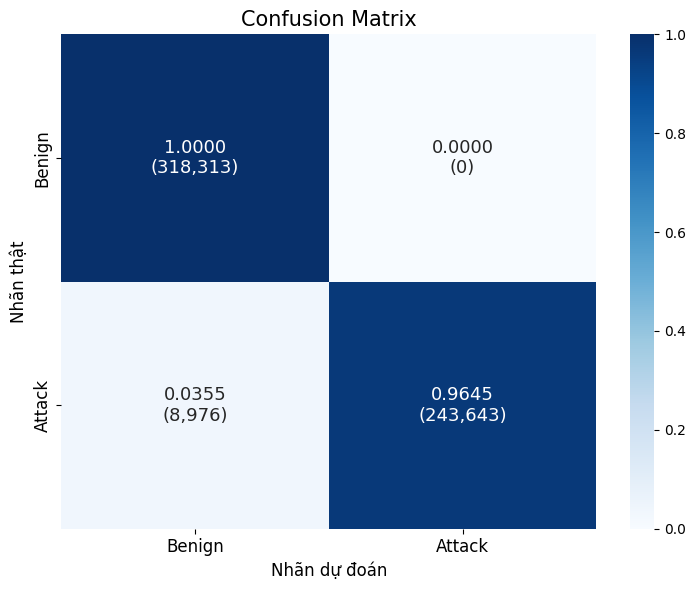

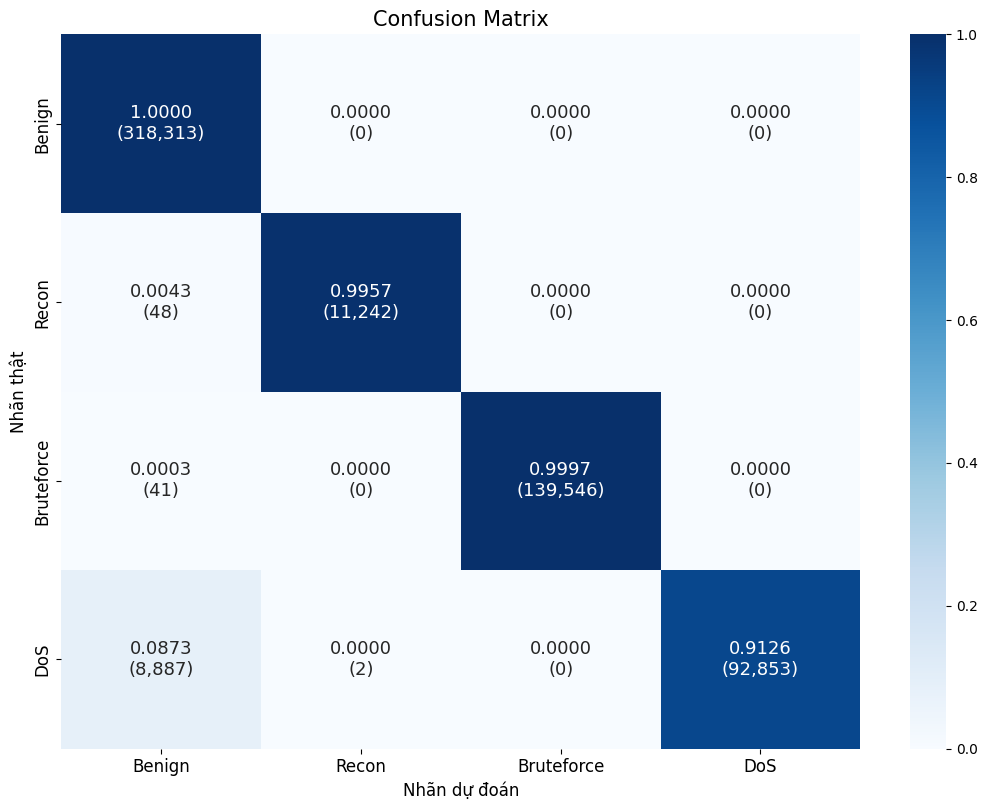

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_cm(y_true, y_pred, labels, names, path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f'{norm[i, j]:.4f}\n({cm[i, j]:,})' for j in range(len(labels))] for i in range(len(labels))])
    fig, ax = plt.subplots(figsize=(7.5, 6) if len(labels) == 2 else (2.2 * len(labels) + 2, 1.6 * len(labels) + 1.8))
    sns.heatmap(norm, annot=annot, fmt='', cmap='Blues', xticklabels=names, yticklabels=names,
                annot_kws={'fontsize': 13}, ax=ax)
    ax.set_title('Confusion Matrix', fontsize=15)
    ax.set_xlabel('Nhãn dự đoán', fontsize=12)
    ax.set_ylabel('Nhãn thật', fontsize=12)
    ax.tick_params(labelsize=12)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    return pd.DataFrame(cm, index=names, columns=names)


te = data['test']
te = te[(te['use_train'] == 1) & (te['incomplete_capture'] == 0)]
for name, m in fitted.items():
    run_dir = MODEL_ROOT / MODEL_DIR[name] / RUN_ID
    sc, cls = score(m, te)
    pred3 = np.where(sc >= thr[name], cls, 'benign')
    print(f'== {name} (ngưỡng {thr[name]:.4f}, {len(te):,} cửa sổ test)')
    cm2 = plot_cm(np.where(te['label'] == 'benign', 'Benign', 'Attack'), np.where(pred3 == 'benign', 'Benign', 'Attack'),
                  ['Benign', 'Attack'], ['Benign', 'Attack'], run_dir / 'confusion_matrix_binary.png')
    cm3 = plot_cm(te['label'], pred3, CLASSES, [CLASS_NAMES[c] for c in CLASSES], run_dir / 'confusion_matrix_multiclass.png')
    cm2.to_csv(run_dir / 'test_confusion_matrix_binary.csv')
    cm3.to_csv(run_dir / 'test_confusion_matrix_multiclass.csv')

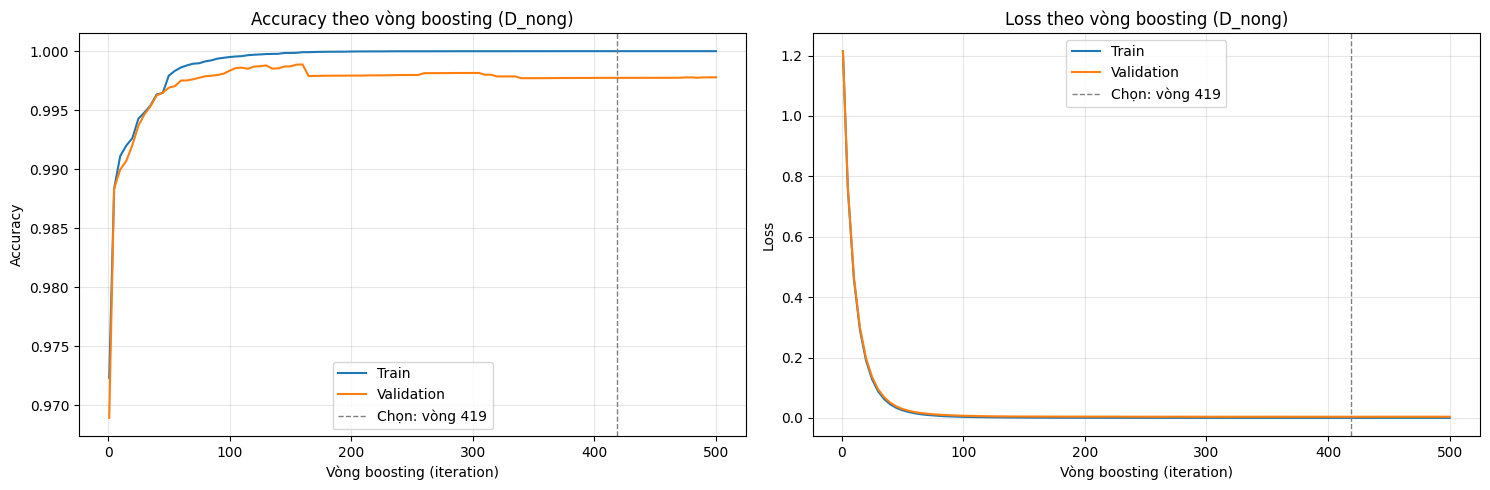

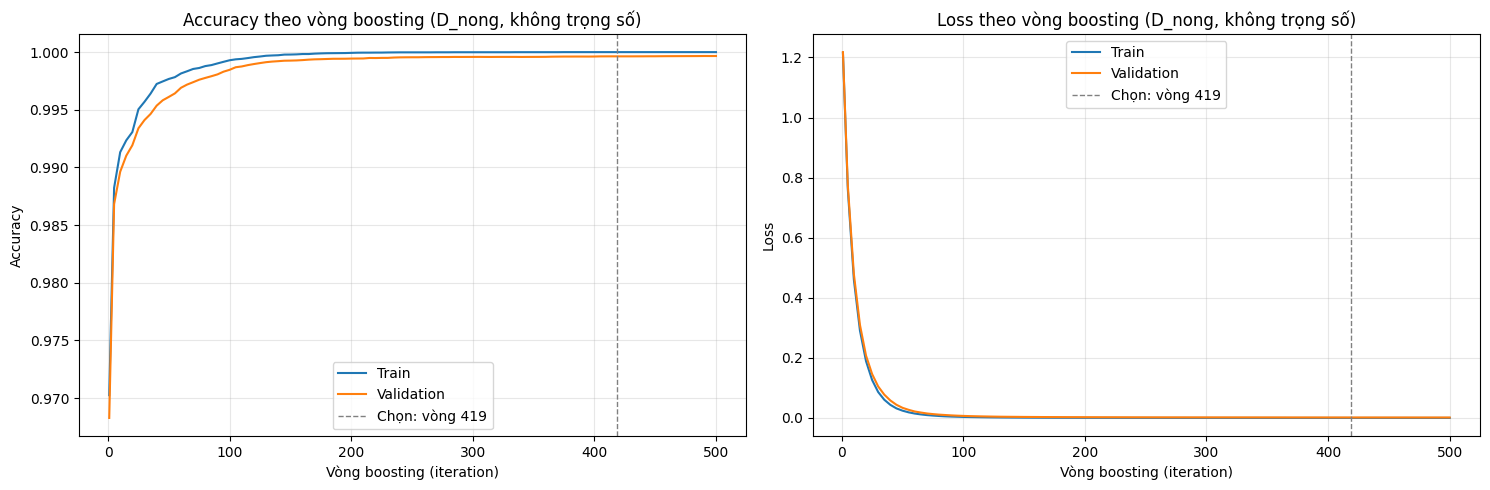

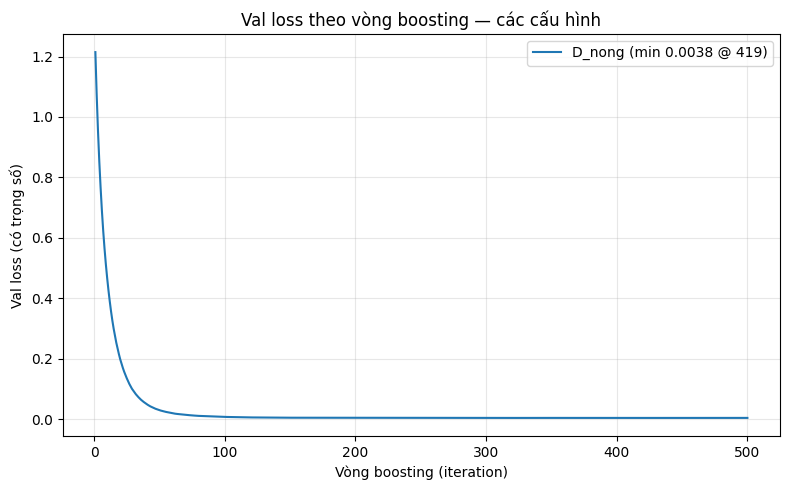

,iteration,train_accuracy,train_loss,train_accuracy_unweighted,train_loss_unweighted,validation_accuracy,validation_loss,validation_accuracy_unweighted,validation_loss_unweighted
0,1,0.9723,1.2140,0.9703,1.2155,0.9689,1.2146,0.9683,1.2177
2,10,0.9911,0.4607,0.9913,0.4602,0.9900,0.4678,0.9896,0.4789
10,50,0.9979,0.0251,0.9977,0.0242,0.9969,0.0294,0.9961,0.0337
84,419,1.0000,0.0000,1.0000,0.0000,0.9977,0.0038,0.9996,0.0015
101,500,1.0000,0.0000,1.0000,0.0000,0.9978,0.0039,0.9997,0.0015


In [11]:
run_dir = MODEL_ROOT / MODEL_DIR['hgb'] / RUN_ID
hist.to_csv(run_dir / 'train_history.csv', index=False)


def plot_history(suffix, path, note):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, metric, title in [(axes[0], 'accuracy', 'Accuracy theo vòng boosting'), (axes[1], 'loss', 'Loss theo vòng boosting')]:
        ax.plot(hist['iteration'], hist[f'train_{metric}{suffix}'], label='Train')
        ax.plot(hist['iteration'], hist[f'validation_{metric}{suffix}'], label='Validation')
        ax.axvline(BEST_ITER, color='gray', linestyle='--', linewidth=1, label=f'Chọn: vòng {BEST_ITER}')
        ax.set_title(f'{title}{note}')
        ax.set_xlabel('Vòng boosting (iteration)')
        ax.set_ylabel('Accuracy' if metric == 'accuracy' else 'Loss')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


plot_history('', run_dir / 'train_history.png', f' ({CFG})')
plot_history('_unweighted', run_dir / 'train_history_unweighted.png', f' ({CFG}, không trọng số)')

fig, ax = plt.subplots(figsize=(8, 5))
for cfg, vl in grid_curves.items():
    ax.plot(np.arange(1, len(vl) + 1), vl, label=f"{cfg} (min {vl.min():.4f} @ {vl.argmin() + 1})")
ax.set_title('Val loss theo vòng boosting — các cấu hình')
ax.set_xlabel('Vòng boosting (iteration)')
ax.set_ylabel('Val loss (có trọng số)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(run_dir / 'config_grid_val_loss.png', dpi=150)
plt.show()
hist[hist['iteration'].isin([1, 10, 50, BEST_ITER, hist['iteration'].max()])].round(4)